# Load Data and Configure Settings

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Refs. for image and text multimodal classification model : https://artelab.dista.uninsubria.it/res/research/papers/2020/2020-IVCNZ-Gallo-Food101.pdf

/kaggle/input/retail-products-classification/train.csv
/kaggle/input/retail-products-classification/test.csv
/kaggle/input/retail-products-classification/test/test/B0000AKOT0.jpg
/kaggle/input/retail-products-classification/test/test/B00001ZT4Q.jpg
/kaggle/input/retail-products-classification/test/test/B0001M0Z0C.jpg
/kaggle/input/retail-products-classification/test/test/B0001K5LWQ.jpg
/kaggle/input/retail-products-classification/test/test/B00AZUD46C.jpg
/kaggle/input/retail-products-classification/test/test/B0000636XQ.jpg
/kaggle/input/retail-products-classification/test/test/B0095QOGYG.jpg
/kaggle/input/retail-products-classification/test/test/B0001M0Y4O.jpg
/kaggle/input/retail-products-classification/test/test/B00004R7OK.jpg
/kaggle/input/retail-products-classification/test/test/B00004SD8Z.jpg
/kaggle/input/retail-products-classification/test/test/B0000304PD.jpg
/kaggle/input/retail-products-classification/test/test/B00029XI30.jpg
/kaggle/input/retail-products-classification/test/t

In [2]:
!pip install torchviz

In [3]:
!pip install --upgrade torchinfo

In [4]:
import torch
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from transformers import DebertaV2Tokenizer, DebertaV2Model
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import matplotlib.pyplot as plt
from PIL import Image
import os
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import TransformerDecoder, TransformerDecoderLayer
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
import matplotlib.pyplot as plt
from torchviz import make_dot
from torchvision import models
from torchinfo import summary
import pprint
import time

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs!")


Using 2 GPUs!


In [6]:
!nvidia-smi

Mon Sep 28 12:34:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [7]:
train_csv_path = '../input/retail-products-classification/train.csv'
test_csv_path = '../input/retail-products-classification/test.csv'
train_images_path = '../input/retail-products-classification/train/train'
test_images_path = '../input/retail-products-classification/test/test'

In [ ]:
# import gc
# del model, train_loader, val_loader  # Delete large objects
# gc.collect()  # Force garbage collection
# torch.cuda.empty_cache()


# import IPython
# IPython.display.clear_output(wait=True)

# import os
# os._exit(00)

# Process Data

In [8]:
df = pd.read_csv(train_csv_path)
df.head()

,ImgId,title,description,categories
0,B000HYL1V6,TUNGSTEN SOLDER PICK WITH HANDLE,Solder Pick for picking up molten solder when ...,"Arts, Crafts & Sewing"
1,B00006HXWY,Write Right 98167 Screen Protector for Sony T615C,We all screen. And we all need to protect thos...,Cell Phones & Accessories
2,B000GAWSBS,Casio Mens DBC310-1 Databank 300 Digital Watch...,"Bringing you precision at a glance, the Casio ...","Clothing, Shoes & Jewelry"
3,B000040JOL,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Tools & Home Improvement
4,B00006IB78,Energizer 2 in 1 Light,This twoway light features a bright flashlight...,Health & Personal Care


In [9]:
df['description'] = df['description'].fillna("").astype(str)

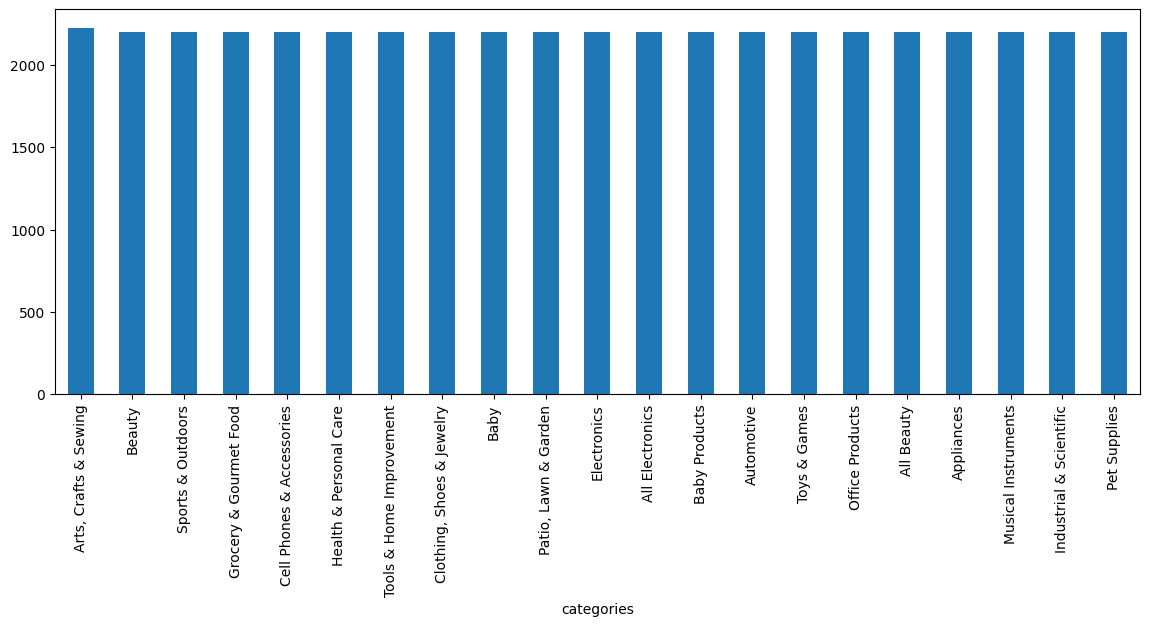

In [10]:
df['categories'].value_counts().plot(kind='bar', figsize=(14, 5));

In [11]:
df.shape

(46229, 4)

## Check whether image exists as ImgId Column

In [12]:
def check_image_exists(img_id, image_dir):
    img_path = os.path.join(image_dir, str(img_id) + '.jpg')
    return os.path.exists(img_path)

In [13]:
df = df[df['ImgId'].apply(lambda x: check_image_exists(x, train_images_path))].reset_index(drop=True)

In [14]:
df.shape

(42000, 4)

In [15]:
test_df = pd.read_csv(test_csv_path)
test_df.tail()

,ImgId,title,description
10591,B00000JDGO,Olympus Stylus Epic DLX 35mm Camera,Product Information\nIf you are passionate abo...
10592,B00BE5DDQI,THERAPY- G by THERAPY- G FOR THINNING OR FINE ...,"Launched by the design house of in , THERAPY- ..."
10593,B00001SIGU,Canon ELPH 260 APS Camera,"An Advanced Photo System camera for beginners,..."
10594,B000182DTM,MSD Ignition 6200 Capacitive Discharge 6A Igni...,"Whether you have a powerful street machine, ha..."
10595,B00009RUCI,Vanguard LITE 1 Tri Pod,A tabletop tripod strong enough for a camera o...


In [16]:
test_df.shape

(10596, 3)

In [17]:
test_df = test_df[test_df['ImgId'].apply(lambda x: check_image_exists(x, test_images_path))].reset_index(drop=True)

In [18]:
test_df.shape

(6367, 3)

In [19]:
len(os.listdir(train_images_path)), len(os.listdir(test_images_path)), df.shape, test_df.shape

(42000, 6367, (42000, 4), (6367, 3))

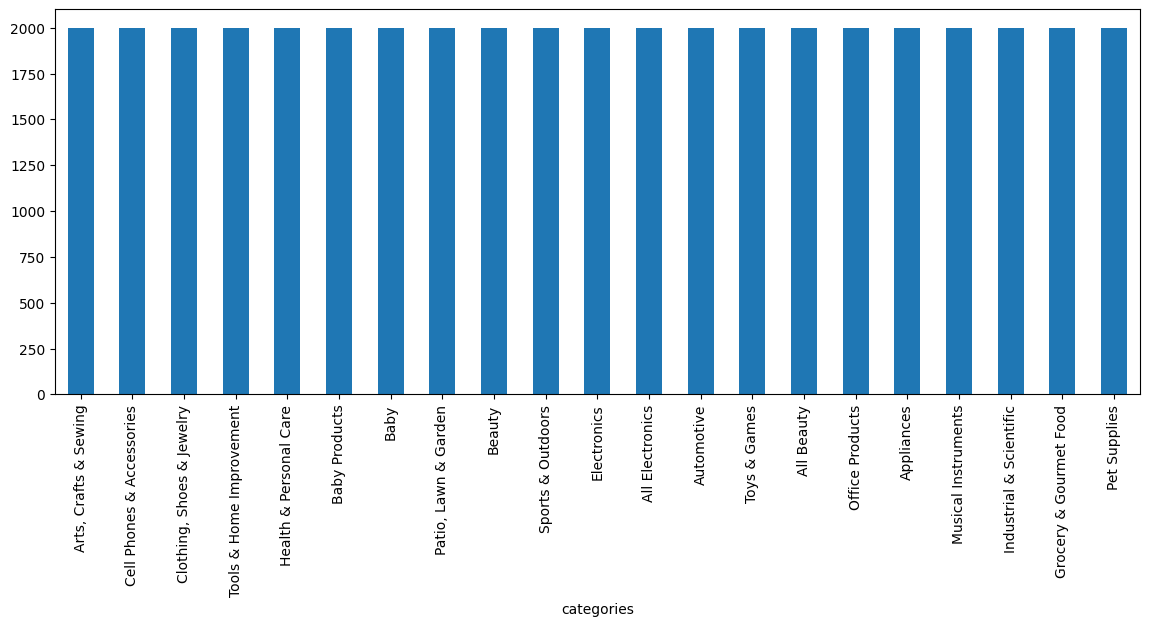

In [20]:
df['categories'].value_counts().plot(kind='bar', figsize=(14, 5));

In [21]:
# Statistical Summary of Text Lengths
print("Title Length Statistics:")
print(df['title'].str.len().describe())
print("\nDescription Length Statistics:")
print(df['description'].str.len().describe())

Title Length Statistics:
count    42000.000000
mean        54.494262
std         29.867824
min          3.000000
25%         36.000000
50%         49.000000
75%         65.000000
max        549.000000
Name: title, dtype: float64

Description Length Statistics:
count    42000.000000
mean       473.923167
std        624.179259
min          0.000000
25%        134.000000
50%        302.000000
75%        589.000000
max      18968.000000
Name: description, dtype: float64


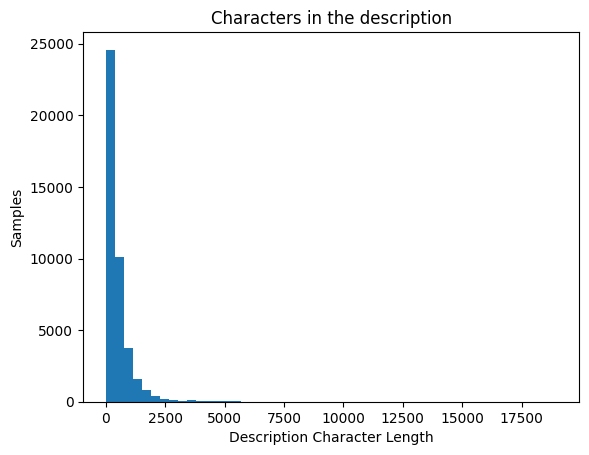

In [22]:
word_len=df['description'].str.len()
plt.hist(word_len, bins=50)
plt.ylabel('Samples')
plt.xlabel('Description Character Length')
plt.title('Characters in the description')
plt.show()

/usr/local/lib/python3.10/dist-packages/numpy/lib/histograms.py:825: RuntimeWarning: invalid value encountered in greater_equal
  keep = (tmp_a >= first_edge)
/usr/local/lib/python3.10/dist-packages/numpy/lib/histograms.py:826: RuntimeWarning: invalid value encountered in less_equal
  keep &= (tmp_a <= last_edge)


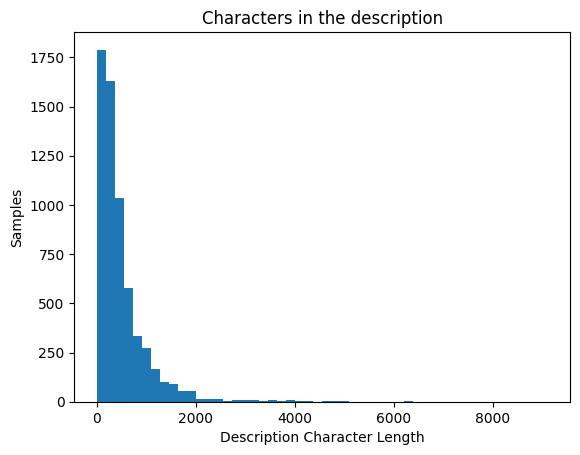

In [23]:
word_len=test_df['description'].str.len()
plt.hist(word_len, bins=50)
plt.ylabel('Samples')
plt.xlabel('Description Character Length')
plt.title('Characters in the description')
plt.show()

In [24]:
# category_mapping = {category: idx for idx, category in enumerate(df['categories'].unique())}
# df['category_numeric'] = df['categories'].map(category_mapping)  # Add numeric labels

# train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['category_numeric'], random_state=42)

# df['category_numeric'].unique()

In [25]:
# Apply One-Hot Encoding to 'categories' column
encoder = OneHotEncoder(sparse=False)
one_hot_labels = encoder.fit_transform(df[['categories']])
category_labels = encoder.categories_[0]
df = df.drop(columns=['categories'])
df[category_labels] = one_hot_labels

/usr/local/lib/python3.10/dist-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


In [26]:
df.head()

,ImgId,title,description,All Beauty,All Electronics,Appliances,"Arts, Crafts & Sewing",Automotive,Baby,Baby Products,...,Grocery & Gourmet Food,Health & Personal Care,Industrial & Scientific,Musical Instruments,Office Products,"Patio, Lawn & Garden",Pet Supplies,Sports & Outdoors,Tools & Home Improvement,Toys & Games
0,B000HYL1V6,TUNGSTEN SOLDER PICK WITH HANDLE,Solder Pick for picking up molten solder when ...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,B00006HXWY,Write Right 98167 Screen Protector for Sony T615C,We all screen. And we all need to protect thos...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,B000GAWSBS,Casio Mens DBC310-1 Databank 300 Digital Watch...,"Bringing you precision at a glance, the Casio ...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,B000040JOL,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,B00006IB78,Energizer 2 in 1 Light,This twoway light features a bright flashlight...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [27]:
# one_hot_labels 
category_labels

array(['All Beauty', 'All Electronics', 'Appliances',
       'Arts, Crafts & Sewing', 'Automotive', 'Baby', 'Baby Products',
       'Beauty', 'Cell Phones & Accessories', 'Clothing, Shoes & Jewelry',
       'Electronics', 'Grocery & Gourmet Food', 'Health & Personal Care',
       'Industrial & Scientific', 'Musical Instruments',
       'Office Products', 'Patio, Lawn & Garden', 'Pet Supplies',
       'Sports & Outdoors', 'Tools & Home Improvement', 'Toys & Games'],
      dtype=object)

## Split Train/Valid Data

In [28]:
train_df, val_df = train_test_split(df, test_size=0.2, stratify=one_hot_labels, random_state=42)


## Configure Image Data Augumentation Setting

In [29]:
'''image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])'''

image_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0,7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),  # Color jitter
    transforms.RandomGrayscale(0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


In [30]:
# tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

## Configure Dataloader

In [31]:
# For RoBERTa
'''class RetailDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None, is_test=False):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.transform = transform
        self.is_test = is_test
        self.tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        img_path = os.path.join(self.img_dir, str(row['ImgId']) + '.jpg')

        # Skip missing files
        if not os.path.exists(img_path):
            return self.__getitem__((idx + 1) % len(self.dataframe))

        # Ensure correct PIL import
        try:
            image = Image.open(img_path).convert('RGB')
        except AttributeError:
            from PIL import Image as PILImage  # Ensure correct Image module is used
            image = PILImage.open(img_path).convert('RGB')
            
        if self.transform:
            image = self.transform(image)

        # # Tokenize title and description separately
        # title_encoding = self.tokenizer(row['title'], padding='max_length', truncation=True, max_length=64, return_tensors='pt')
        # desc_encoding = self.tokenizer(row['description'], padding='max_length', truncation=True, max_length=512, return_tensors='pt')

        # # Concatenate title and description
        # input_ids = torch.cat([title_encoding['input_ids'], desc_encoding['input_ids']], dim=1)
        # attention_mask = torch.cat([title_encoding['attention_mask'], desc_encoding['attention_mask']], dim=1)

        # if self.is_test:
        #     return image, input_ids.squeeze(0), attention_mask.squeeze(0), row['ImgId']

        # label = torch.tensor(row[category_labels].astype(float).values, dtype=torch.float32)  # Use one-hot encoding
        # return image, input_ids.squeeze(0), attention_mask.squeeze(0), label        

        combined_text = row['title'] + " </s> " + row['description']
        encoding = self.tokenizer(
            combined_text,
            padding='max_length',
            truncation=True,
            max_length=512,
            return_tensors='pt'
        )
        
        label = torch.tensor(row[category_labels].astype(float).values, dtype=torch.float32)  # Use one-hot encoding
        return image, encoding['input_ids'].squeeze(0), encoding['attention_mask'].squeeze(0), label
'''

# For ELECTRa
'''class RetailDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None, is_test=False):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.transform = transform
        self.is_test = is_test
        self.tokenizer = ElectraTokenizer.from_pretrained('google/electra-base-discriminator')

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        img_path = os.path.join(self.img_dir, str(row['ImgId']) + '.jpg')

        # Skip missing files
        if not os.path.exists(img_path):
            return self.__getitem__((idx + 1) % len(self.dataframe))

        try:
            image = Image.open(img_path).convert('RGB')
        except AttributeError:
            from PIL import Image as PILImage
            image = PILImage.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        # Combine title and description
        combined_text = row['title'] + " [SEP] " + row['description']  # ELECTRA supports [SEP] for separation
        encoding = self.tokenizer(
            combined_text,
            padding='max_length',
            truncation=True,
            max_length=512,
            return_tensors='pt'
        )

        label = torch.tensor(row[category_labels].astype(float).values, dtype=torch.float32)
        return image, encoding['input_ids'].squeeze(0), encoding['attention_mask'].squeeze(0), label
'''
# For DeBERTaV3
class RetailDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None, is_test=False):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.transform = transform
        self.is_test = is_test
        self.tokenizer = DebertaV2Tokenizer.from_pretrained("microsoft/deberta-v3-base")

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        img_path = os.path.join(self.img_dir, str(row['ImgId']) + '.jpg')

        # Skip missing files
        if not os.path.exists(img_path):
            return self.__getitem__((idx + 1) % len(self.dataframe))

        try:
            image = Image.open(img_path).convert('RGB')
        except AttributeError:
            from PIL import Image as PILImage
            image = PILImage.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        # Combine title and description
        combined_text = row['title'] + " </s> " + row['description']
        encoding = self.tokenizer(
            combined_text,
            padding='max_length',
            truncation=True,
            max_length=512,
            return_tensors='pt'
        )

        label = torch.tensor(row[category_labels].astype(float).values, dtype=torch.float32)
        return image, encoding['input_ids'].squeeze(0), encoding['attention_mask'].squeeze(0), label

### Run before if you already have trained and load the model

In [32]:
train_dataset = RetailDataset(train_df, train_images_path, transform=image_transform)
val_dataset = RetailDataset(val_df, train_images_path, transform=image_transform)
# test_dataset = RetailDataset(test_df, test_images_path, transform=image_transform, is_test=True)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=4)
# test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=4)

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

## Build Model (Image Model(128 features) : EfficientNet_B0 base, Text Model(128 features) : DeBERTaV3(frozen)-TransformerDecoder(2 layers) -> Concat. to build multi modal model)

In [33]:
class ImageModel(nn.Module):
    def __init__(self):
        super(ImageModel, self).__init__()
        # base_image_model = models.mobilenet_v3_large(pretrained=True)
        base_image_model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
        
        for param in base_image_model.parameters():
            param.requires_grad = True

        self.feature_extractor = nn.Sequential(
            base_image_model.features,
            nn.AdaptiveAvgPool2d((1, 1)) # Pool to fixed size 
        )
        
        self.dropout = nn.Dropout(p=0.2)
        self.fc = nn.Linear(1280, 128)  # EfficientNet-B0 output size = 1280
        self.norm = nn.LayerNorm(128)  # Added LayerNorm

    
    def forward(self, image):    
        features = self.feature_extractor(image)    
        features = self.dropout(features)    
        features = torch.flatten(features, start_dim=1)    
        features = self.fc(features)    
        features = F.relu(features)    
        features = self.norm(features)  # Apply LayerNorm    
        features = F.normalize(features, p=2, dim=1)    
        return features  


class TextModel(nn.Module):
    def __init__(self, freeze_layers=True, num_queries=4, num_decoder_layers=2):
        super(TextModel, self).__init__()
        self.text_model = DebertaV2Model.from_pretrained("microsoft/deberta-v3-base")

        if freeze_layers:
            for param in self.text_model.parameters():
                param.requires_grad = False
            for param in self.text_model.encoder.layer[-1].parameters():
                param.requires_grad = True

        hidden_size = self.text_model.config.hidden_size  # typically 768
        decoder_dim = 128
        self.fc = nn.Linear(hidden_size, decoder_dim)
        self.norm = nn.LayerNorm(decoder_dim)

        decoder_layer = TransformerDecoderLayer(d_model=decoder_dim, nhead=8, dim_feedforward=512, batch_first=True)
        self.decoder = TransformerDecoder(decoder_layer, num_layers=num_decoder_layers)

        self.num_queries = num_queries
        self.learned_queries = nn.Parameter(torch.randn(self.num_queries, decoder_dim))  # Learnable query

        self.projection = nn.Linear(decoder_dim, 128)  # Final projection to match original feature size

    def forward(self, input_ids, attention_mask):
        encoder_output = self.text_model(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        text_features = self.fc(encoder_output)  
        text_features = F.relu(text_features)
        text_features = self.norm(text_features)

        # Prepare a learned query vector (decoder input)
        batch_size = input_ids.size(0)
        queries = self.learned_queries.unsqueeze(0).expand(batch_size, -1, -1)  # [batch, num_queries, decoder_dim]
        decoded = self.decoder(tgt=queries, memory=text_features)  # [batch, num_queries, decoder_dim]
        pooled = decoded.mean(dim=1)  # Average over queries
        return self.projection(pooled)  # [batch, decoder_dim]


class MultiModalModel(nn.Module):    
    def __init__(self, num_classes):    
        super(MultiModalModel, self).__init__()    
        self.image_model = ImageModel()    
        self.text_model = TextModel() 
            
        self.dense = nn.Linear(256, 256)    
        self.fc = nn.Linear(256, num_classes)    

    
    def forward(self, image, input_ids, attention_mask):    
        img_features = self.image_model(image)    
        text_features = self.text_model(input_ids, attention_mask)  

        combined = torch.cat((img_features, text_features), dim=1)    
        combined = self.dense(combined)    
        combined = F.relu(combined)    
        output = self.fc(combined)    
        return output  

In [34]:
# num_classes = len(df['categories'].unique())
num_classes = len(category_labels)

## Visualize Model

In [35]:

# Create dummy inputs
# tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
tokenizer = DebertaV2Tokenizer.from_pretrained("microsoft/deberta-v3-base")
dummy_text = "Sample text for model visualization"
encoded_input = tokenizer(dummy_text, padding="max_length", truncation=True, max_length=64, return_tensors="pt")

dummy_image = torch.randn(1, 3, 224, 224).to(device)
dummy_input_ids = encoded_input["input_ids"].to(device)
dummy_attention_mask = encoded_input["attention_mask"].to(device)

multimodalmodel = MultiModalModel(num_classes)
multimodalmodel.to(device)
outputs = multimodalmodel(dummy_image, dummy_input_ids, dummy_attention_mask)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:00<00:00, 77.9MB/s]


pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

In [36]:
print("Image Sample Shape:", dummy_image.shape, "Dtype:", dummy_image.dtype)
print("Text Sample Shape:", dummy_input_ids.shape, "Dtype:", dummy_input_ids.dtype)
print("Attention Mask Shape:", dummy_attention_mask.shape, "Dtype:", dummy_attention_mask.dtype)

Image Sample Shape: torch.Size([1, 3, 224, 224]) Dtype: torch.float32
Text Sample Shape: torch.Size([1, 64]) Dtype: torch.int64
Attention Mask Shape: torch.Size([1, 64]) Dtype: torch.int64


In [37]:
# Generate model visualization
dot = make_dot(outputs, params=dict(multimodalmodel.named_parameters()))
dot.format = 'png'
dot.render('multi_modal_model')  # Saves as multi_modal_model.png

'multi_modal_model.png'

In [38]:
# Display visualization
from IPython.display import Image
Image('multi_modal_model.png')

In [39]:
# Initialize model
image_model = ImageModel().to(device)
text_model = TextModel().to(device)


In [40]:
# Get ImageModel Summary
summary(image_model, input_data=[dummy_image], col_names=["input_size", "output_size", "num_params", "trainable"])

Layer (type:depth-idx)                                       Input Shape               Output Shape              Param #                   Trainable
ImageModel                                                   [1, 3, 224, 224]          [1, 128]                  --                        True
├─Sequential: 1-1                                            [1, 3, 224, 224]          [1, 1280, 1, 1]           --                        True
│    └─Sequential: 2-1                                       [1, 3, 224, 224]          [1, 1280, 7, 7]           --                        True
│    │    └─Conv2dNormActivation: 3-1                        [1, 3, 224, 224]          [1, 32, 112, 112]         928                       True
│    │    └─Sequential: 3-2                                  [1, 32, 112, 112]         [1, 16, 112, 112]         1,448                     True
│    │    └─Sequential: 3-3                                  [1, 16, 112, 112]         [1, 24, 56, 56]           16,714            

In [41]:
# Get TextModel Summary
summary(text_model, input_data=[dummy_input_ids, dummy_attention_mask], col_names=["input_size", "output_size", "num_params", "trainable"])

Layer (type:depth-idx)                                            Input Shape               Output Shape              Param #                   Trainable
TextModel                                                         [1, 64]                   [1, 128]                  512                       Partial
├─DebertaV2Model: 1-1                                             --                        [1, 64, 768]              --                        Partial
│    └─DebertaV2Embeddings: 2-1                                   --                        [1, 64, 768]              --                        False
│    │    └─Embedding: 3-1                                        [1, 64]                   [1, 64, 768]              (98,380,800)              False
│    │    └─LayerNorm: 3-2                                        [1, 64, 768]              [1, 64, 768]              (1,536)                   False
│    │    └─Dropout: 3-3                                          [1, 64, 768]              

In [42]:
# Get Model Summary
summary(multimodalmodel, input_data=[dummy_image, dummy_input_ids, dummy_attention_mask], col_names=["input_size", "output_size", "num_params", "trainable"])

Layer (type:depth-idx)                                                 Input Shape               Output Shape              Param #                   Trainable
MultiModalModel                                                        [1, 3, 224, 224]          [1, 21]                   --                        Partial
├─ImageModel: 1-1                                                      [1, 3, 224, 224]          [1, 128]                  --                        True
│    └─Sequential: 2-1                                                 [1, 3, 224, 224]          [1, 1280, 1, 1]           --                        True
│    │    └─Sequential: 3-1                                            [1, 3, 224, 224]          [1, 1280, 7, 7]           4,007,548                 True
│    │    └─AdaptiveAvgPool2d: 3-2                                     [1, 1280, 7, 7]           [1, 1280, 1, 1]           --                        --
│    └─Dropout: 2-2                                                   

In [43]:
del image_model, text_model, multimodalmodel
del dummy_image, dummy_input_ids, dummy_attention_mask

## Configure Optimizer

In [44]:
model = MultiModalModel(num_classes)

In [45]:
# def get_optimizer_scheduler(model, learning_rate=0.001, max_lr=0.001, epochs=num_epochs, pct_start=0.1):
#     optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)  # Use AdamW for better stability
#     scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lr, steps_per_epoch=len(train_loader), epochs=num_epochs, pct_start=0.1)  # Warmup + Cosine annealing schedule
#     return optimizer, scheduler

In [46]:

# model_path = 'multimodal.pth'
# if os.path.exists(model_path):
#     model.load_state_dict(torch.load(model_path))
#     print("Model loaded successfully from", model_path)
# else:
#     print("No saved model found. Training from scratch.")
# model.to(device)
pos_weight = (1 - df[category_labels].mean()) / df[category_labels].mean()
# pos_weight = torch.tensor(pos_weight.values, dtype=torch.float32)  # keep on CPU initially
pos_weight = torch.tensor(pos_weight.values, dtype=torch.float32)

optimizer = optim.AdamW([
    {"params": model.image_model.parameters(), "lr": 2e-3},
    {"params": model.text_model.parameters(), "lr": 2e-3},
    {"params": model.dense.parameters(), "lr": 5e-3},
    {"params": model.fc.parameters(), "lr": 5e-3}
], weight_decay=1e-4)

# Train Model

In [47]:
def train_model(model, train_loader, val_loader, pos_weight, optimizer, num_epochs=15, accumulation_steps=4):
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    scaler = torch.amp.GradScaler()  # Fixed AMP scaler initialization

    model = model.to(device)

    if torch.cuda.device_count() > 1:
        model = nn.DataParallel(model, device_ids=[0, 1])

    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=3, T_mult=2, eta_min=1e-6
    )

    train_losses, val_losses = [], []
    train_f1s, val_f1s = [], []
    train_accuracies, val_accuracies = [], []
    train_precisions, val_precisions = [], []
    train_recalls, val_recalls = [], []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        all_preds, all_labels = [], []
        start_time = time.time()

        optimizer.zero_grad(set_to_none=True)  # Prevent memory leaks

        for i, (images, input_ids, attention_masks, labels) in enumerate(train_loader):
            images, input_ids, attention_masks, labels = (
                images.to(device, non_blocking=True),
                input_ids.to(device, non_blocking=True),
                attention_masks.to(device, non_blocking=True),
                labels.to(device, non_blocking=True)
            )

            criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))

            with torch.autocast(device_type="cuda"):
                outputs = model(images, input_ids, attention_masks)
                loss = criterion(outputs, labels)
                loss = loss / accumulation_steps  # Scale loss for gradient accumulation

            scaler.scale(loss).backward()

            if (i + 1) % accumulation_steps == 0 or (i + 1) == len(train_loader):
                if torch.isnan(loss).any():
                    print(f"❌ Warning: NaN detected in loss at step {i+1}")
                    continue  # Skip step if NaN is found

                # Ensure gradients exist before stepping optimizer
                if any(p.grad is not None for p in model.parameters()):
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)  # Reset gradients properly
                else:
                    print(f"⚠️ Warning: No gradients computed at step {i+1}. Skipping optimizer step.")

            running_loss += loss.item() * accumulation_steps
            all_preds.append(outputs.detach().cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            
            

        scheduler.step()

        train_loss = running_loss / len(train_loader)
        # train_preds = (np.vstack(all_preds) > 0.5).astype(int) # For multi-label classification
        # train_labels = np.vstack(all_labels)
        train_preds = np.argmax(np.vstack(all_preds), axis=1) # For multi-class classification
        train_labels = np.argmax(np.vstack(all_labels), axis=1) 
        
        # Compute training metrics
        train_f1 = f1_score(train_labels, train_preds, average='macro')
        train_accuracy = accuracy_score(train_labels, train_preds)
        train_precision = precision_score(train_labels, train_preds, average='macro', zero_division=0)
        train_recall = recall_score(train_labels, train_preds, average='macro', zero_division=0)
        
        train_losses.append(train_loss)
        train_f1s.append(train_f1)
        train_accuracies.append(train_accuracy)
        train_precisions.append(train_precision)
        train_recalls.append(train_recall)

        epoch_time = time.time() - start_time

        # print(np.vstack(all_labels).shape, train_preds.shape)

        # Validation Step
        model.eval()
        val_loss = 0.0
        val_preds, val_labels = [], []
        val_start_time = time.time()

        with torch.no_grad():
            for images, input_ids, attention_masks, labels in val_loader:
                images, input_ids, attention_masks, labels = (
                    images.to(device, non_blocking=True),
                    input_ids.to(device, non_blocking=True),
                    attention_masks.to(device, non_blocking=True),
                    labels.to(device, non_blocking=True)
                )

                criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))
                outputs = model(images, input_ids, attention_masks)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

                val_preds.append(outputs.cpu().numpy())
                val_labels.append(labels.cpu().numpy())

        val_loss /= len(val_loader)
        # val_preds_binary = (np.vstack(val_preds) > 0.5).astype(int) # For multi-label classification
        # val_labels = np.vstack(val_labels)
        val_preds_binary = np.argmax(np.vstack(val_preds), axis=1) # For multi-class classification
        val_labels = np.argmax(np.vstack(val_labels), axis=1)  # Ensure labels are also in class index format


        # Compute validation metrics
        val_f1 = f1_score(val_labels, val_preds_binary, average='macro')
        val_accuracy = accuracy_score(val_labels, val_preds_binary)
        val_precision = precision_score(val_labels, val_preds_binary, average='macro', zero_division=0)
        val_recall = recall_score(val_labels, val_preds_binary, average='macro', zero_division=0)

        val_losses.append(val_loss)
        val_f1s.append(val_f1)
        val_accuracies.append(val_accuracy)
        val_precisions.append(val_precision)
        val_recalls.append(val_recall)

        val_time = time.time() - val_start_time

        print(f"Epoch: {epoch+1}/{num_epochs}, \n" 
              f"Train Loss: {train_loss:.4f}, Train F1: {train_f1:.4f}, Train Acc: {train_accuracy:.4f}, Train Prec: {train_precision:.4f}, Train Rec: {train_recall:.4f}, Train Time: {epoch_time:.2f}s, \n"
              f"Val Loss: {val_loss:.4f}, Val F1: {val_f1:.4f}, Val Acc: {val_accuracy:.4f}, Val Prec: {val_precision:.4f}, Val Rec: {val_recall:.4f}, Val Time: {val_time:.2f}s")

        torch.cuda.empty_cache()  # Free memory

    return train_losses, val_losses, train_f1s, val_f1s, train_accuracies, val_accuracies, train_precisions, val_precisions, train_recalls, val_recalls


In [ ]:
train_losses, val_losses, train_f1s, val_f1s, train_accuracies, val_accuracies, train_precisions, val_precisions, train_recalls, val_recalls = train_model(
    model, train_loader, val_loader, pos_weight, optimizer, num_epochs=10
)

In [ ]:
# train_losses, val_losses, train_f1s, val_f1s = train_model(model, train_loader, val_loader, pos_weight, optimizer, num_epochs=15)

## Plot Training Procedure

In [ ]:
# plt.figure(figsize=(12, 5))

# # Plot Loss
# plt.subplot(1, 2, 1)
# plt.plot(range(1, 11), train_losses, label='Train Loss')
# plt.plot(range(1, 11), val_losses, label='Validation Loss')
# plt.xlabel('Epochs')
# plt.ylabel('Loss')
# plt.title('Training & Validation Loss')
# plt.legend()

# # Plot F1-Score
# plt.subplot(1, 2, 2)
# plt.plot(range(1, 11), train_f1s, label='Train F1')
# plt.plot(range(1, 11), val_f1s, label='Validation F1')
# plt.xlabel('Epochs')
# plt.ylabel('F1 Score')
# plt.title('Training & Validation F1 Score')
# plt.legend()

# plt.show()

# epochs = range(1, len(train_losses) + 1)

# # Plot Loss
# plt.figure(figsize=(10, 4))
# plt.plot(epochs, train_losses, label="Train Loss", marker='o')
# plt.plot(epochs, val_losses, label="Validation Loss", marker='o')
# plt.xlabel("Epochs")
# plt.ylabel("Loss")
# plt.title("Train vs Validation Loss")
# plt.legend()
# plt.show()

# # Plot F1 Score
# plt.figure(figsize=(10, 4))
# plt.plot(epochs, train_f1s, label="Train F1 Score", marker='o')
# plt.plot(epochs, val_f1s, label="Validation F1 Score", marker='o')
# plt.xlabel("Epochs")
# plt.ylabel("F1 Score")
# plt.title("Train vs Validation F1 Score")
# plt.legend()
# plt.show()

## Save Model

In [ ]:
torch.save({
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
}, 'multimodal_checkpoint.pth')


## Load the Model (If stopped before finished)

In [ ]:
# # Define the model
# num_classes = len(category_labels)
# model = MultiModalModel(num_classes).to(device)

# # Define the optimizer
# optimizer = optim.AdamW([
#     {"params": model.image_model.parameters(), "lr": 1e-5},
#     {"params": model.text_model.parameters(), "lr": 1e-5},
#     {"params": model.dense.parameters(), "lr": 1e-4},
#     {"params": model.fc.parameters(), "lr": 1e-4}
# ], weight_decay=1e-4)

# # Define the scheduler
# scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
#     optimizer, T_0=3, T_mult=2, eta_min=1e-6
# )

# # Load the checkpoint
# checkpoint = torch.load('multimodal_checkpoint.pth', map_location=device)

# # Restore model and optimizer states
# model.load_state_dict(checkpoint['model_state_dict'])
# optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

# # Restore scheduler state if available
# if checkpoint['scheduler_state_dict']:
#     scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

# # Restore previous metrics
# train_losses = checkpoint['train_losses']
# val_losses = checkpoint['val_losses']
# train_f1s = checkpoint['train_f1s']
# val_f1s = checkpoint['val_f1s']

# # Start training from the next epoch
# start_epoch = checkpoint['epoch'] + 1

# print(f"✅ Loaded model and optimizer, resuming from epoch {start_epoch}.")

# # Continue Training
# train_losses, val_losses, train_f1s, val_f1s = train_model(
#     model, train_loader, val_loader, pos_weight, optimizer,
#     num_epochs=15, accumulation_steps=4  # You can change num_epochs as needed
# )


# Fine-tune Base Model

## Unfreeze All Layers

In [ ]:
!pip install peft

In [ ]:
from peft import get_peft_model, LoraConfig, TaskType, PeftModel
from transformers import AutoModel

In [ ]:
# import os
# os._exit(00)

In [ ]:
!nvidia-smi

In [ ]:
# del train_loader, val_loader  # Delete large objects
# del model
# del optimizer
# del image_model
# del text_model
# del multimodalmodel
# del train_dataset
# del val_dataset
# del pos_weight
# del loss
# try:
#     del model
#     del model.module
#     del optimizer
# except:
#     pass
# for var in ['images', 'input_ids', 'attention_masks', 'labels', 'outputs', 'loss']:
#     if var in locals():
#         del globals()[var]
# del train_losses, val_losses
# del train_f1s, val_f1s
# del train_accuracies, val_accuracies 
# del train_precisions, val_precisions 
# del train_recalls, val_recalls
# del val_preds, val_labels 


torch.cuda.empty_cache()
gc.collect()  # Force garbage collection

In [ ]:
# # Create base Roberta
# base_model = RobertaModel.from_pretrained("roberta-base")

# # Define LoRA config
# lora_config = LoraConfig(
#     r=8,                        # Low-rank dimension
#     lora_alpha=32,
#     target_modules=["query", "value"],  # LoRA inside attention layers
#     lora_dropout=0.1,
#     bias="none",
#     task_type=TaskType.SEQ_CLS,
# )

# # Apply LoRA
# lora_roberta = get_peft_model(base_model, lora_config)

In [ ]:
class ImageModel(nn.Module):
    def __init__(self, fine_tune=False):
        super(ImageModel, self).__init__()
        base_image_model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

        # Fine-tune entire model if specified
        for param in base_image_model.parameters():
            param.requires_grad = fine_tune  # If fine_tune=True, unfreeze all layers

        self.feature_extractor = nn.Sequential(
            base_image_model.features,
            nn.AdaptiveAvgPool2d((1, 1))  # Pool to fixed size 
        )

        self.dropout = nn.Dropout(p=0.2)
        self.fc = nn.Linear(1280, 128)
        self.norm = nn.LayerNorm(128)

    def forward(self, image):    
        features = self.feature_extractor(image)    
        features = self.dropout(features)    
        features = torch.flatten(features, start_dim=1)    
        features = self.fc(features)    
        features = F.relu(features)    
        features = self.norm(features)  
        features = F.normalize(features, p=2, dim=1)    
        return features 




class Attention(nn.Module):
    def __init__(self, hidden_dim):
        super(Attention, self).__init__()
        self.attn = nn.Linear(hidden_dim, 1)

    
    def forward(self, lstm_output):
        attn_weights = F.softmax(self.attn(lstm_output), dim=1)  # Compute attention scores
        weighted_output = torch.sum(attn_weights * lstm_output, dim=1)  # Apply attention
        return weighted_output



class TextModel(nn.Module):
    def __init__(self, fine_tune=False):
        super(TextModel, self).__init__()
        self.text_model = RobertaModel.from_pretrained("roberta-base")

        # Fine-tune entire model if specified
        for param in self.text_model.parameters():
            param.requires_grad = fine_tune

        self.fc = nn.Linear(768, 256)
        self.norm = nn.LayerNorm(256)
        self.lstm = nn.LSTM(input_size=256, hidden_size=128, batch_first=True)
        self.attention = Attention(128)

    def forward(self, input_ids, attention_mask):    
        text_features = self.text_model(input_ids, attention_mask=attention_mask).last_hidden_state[:, 0, :]    
        text_features = self.fc(text_features)    
        text_features = F.relu(text_features)    
        text_features = self.norm(text_features)   

        text_features = text_features.unsqueeze(1)    
        lstm_out, _ = self.lstm(text_features)    
        text_features = self.attention(lstm_out)   
        return text_features  




class MultiModalModel(nn.Module):    
    def __init__(self, num_classes, fine_tune=True):    
        super(MultiModalModel, self).__init__()    
        self.image_model = ImageModel(fine_tune=fine_tune)    
        self.text_model = TextModel(fine_tune=fine_tune) 
            
        self.dense = nn.Linear(256, 256)    
        self.fc = nn.Linear(256, num_classes)    

    
    def forward(self, image, input_ids, attention_mask):    
        img_features = self.image_model(image)    
        text_features = self.text_model(input_ids, attention_mask)  

        combined = torch.cat((img_features, text_features), dim=1)    
        combined = self.dense(combined)    
        combined = F.relu(combined)    
        output = self.fc(combined)    
        return output  


## Load the Pretrained Model and Unfreeze Layers

In [ ]:
# Load the trained multimodal model
checkpoint = torch.load('/kaggle/input/multimodal/pytorch/default/1/multimodal_checkpoint.pth', map_location='cpu')
state_dict = checkpoint["model_state_dict"]

# # Filter out incompatible keys related to text_model
# filtered_state_dict = {
#     k: v for k, v in state_dict.items() if not k.startswith("text_model.")
# }

# Initialize models with fine-tuning enabled
image_model = ImageModel(fine_tune=True).to(device)
text_model = TextModel(fine_tune=True).to(device)
num_classes = len(category_labels)
model = MultiModalModel(num_classes,fine_tune=True).to(device)

# Load partial weights
model.load_state_dict(state_dict)

## Define a Lower Learning Rate

In [ ]:
pos_weight = (1 - df[category_labels].mean()) / df[category_labels].mean()
pos_weight = torch.tensor(pos_weight.values, dtype=torch.float32)

optimizer = optim.AdamW([
    {"params": model.image_model.parameters(), "lr": 5e-6},  # Lower LR for image model
    {"params": model.text_model.parameters(), "lr": 5e-6},  # Lower LR for text model
    {"params": model.dense.parameters(), "lr": 1e-4},  # Normal LR for classification layers
    {"params": model.fc.parameters(), "lr": 1e-4}
], weight_decay=1e-4)


## Summarize Models (after unfreezing)

In [ ]:

# Create dummy inputs
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
dummy_text = "Sample text for model visualization"
encoded_input = tokenizer(dummy_text, padding="max_length", truncation=True, max_length=64, return_tensors="pt")

dummy_image = torch.randn(1, 3, 224, 224).to(device)
dummy_input_ids = encoded_input["input_ids"].to(device)
dummy_attention_mask = encoded_input["attention_mask"].to(device)

multimodalmodel = MultiModalModel(num_classes)
multimodalmodel.to(device)


In [ ]:
# Get ImageModel Summary
summary(image_model, input_data=[dummy_image], col_names=["input_size", "output_size", "num_params", "trainable"])

In [ ]:
# Get TextModel Summary
summary(text_model, input_data=[dummy_input_ids, dummy_attention_mask], col_names=["input_size", "output_size", "num_params", "trainable"])

In [ ]:
# Get Model Summary
summary(multimodalmodel, input_data=[dummy_image, dummy_input_ids, dummy_attention_mask], col_names=["input_size", "output_size", "num_params", "trainable"])

In [ ]:
import gc

del image_model
del text_model
del multimodalmodel


gc.collect()  # Force garbage collection
torch.cuda.empty_cache()

In [ ]:
train_dataset = RetailDataset(train_df, train_images_path, transform=image_transform)
val_dataset = RetailDataset(val_df, train_images_path, transform=image_transform)
# test_dataset = RetailDataset(test_df, test_images_path, transform=image_transform, is_test=True)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4)
# test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)

In [ ]:
train_losses, val_losses, train_f1s, val_f1s, train_accuracies, val_accuracies, train_precisions, val_precisions, train_recalls, val_recalls = train_model(
    model, train_loader, val_loader, pos_weight, optimizer, num_epochs=5)

In [ ]:
pp = pprint.PrettyPrinter(indent=4)
pp.pprint(model.state_dict())

In [ ]:
!ls

In [ ]:
!pwd

In [ ]:
'''reverse_category_mapping = {idx: category for category, idx in category_mapping.items()}
test_df['categories'] = test_df['category_numeric'].map(reverse_category_mapping)
test_df.to_csv('test_predictions.csv', index=False)'''

In [ ]:
'''def predict_test_data(model, test_loader, category_mapping, output_csv='test_predictions.csv'):
    model.eval()
    predictions = []
    img_ids = []
    reverse_category_mapping = {v: k for k, v in category_mapping.items()}  # Convert index back to category name
    
    with torch.no_grad():
        for images, input_ids, attention_masks, img_id in test_loader:
            images, input_ids, attention_masks = images.to(device), input_ids.to(device), attention_masks.to(device)
            outputs = model(images, input_ids, attention_masks)
            _, predicted = torch.max(outputs, 1)
            predictions.extend([reverse_category_mapping[pred.item()] for pred in predicted])
            img_ids.extend(img_id)
    
    test_df = pd.read_csv(test_csv_path)
    test_df = test_df[test_df['ImgId'].apply(lambda x: check_image_exists(x, test_images_path))].reset_index(drop=True)
    test_df['categories'] = test_df['ImgId'].map(lambda x: reverse_category_mapping.get(x, 'Unknown'))
    test_df.to_csv(output_csv, index=False)
    print(f"Predictions saved to {output_csv}")'''

In [ ]:
# predict_test_data(model, test_loader, category_mapping, output_csv='test_predictions.csv')